# Examen 1 corregido
David Farías Rivera · 754381

En mi examen solo alcancé a importar las librerías, leer los datos e intentar un `lr.fit` que marcó error. Aquí lo rehago completo con lo que vimos en los laboratorios R1 a R5. En cada error de mi examen contesto cuál fue, cuál es la corrección, por qué lo cometí y cómo evitarlo.

El objetivo es explicar y (continua) con x1, x2, x3 (numéricas) y grupo (A, B o C). Para los modelos solo uso sklearn.

## 1. EDA y limpieza

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import KFold, LeaveOneOut, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

Uso pandas y numpy para manejar los datos, matplotlib para las gráficas y sklearn para los modelos y la validación cruzada.

¿Cuál fue el error? Importé `variance_inflation_factor` de statsmodels y solo se podía usar sklearn.

¿Cuál es la corrección? Lo quité. El VIF lo calculo más abajo con `LinearRegression`.

¿Por qué se cometió el error? Copié los imports del notebook de clase sin leer bien las reglas.

¿Cómo evitarlo en el futuro? Leer las instrucciones antes de empezar e importar solo lo que voy a usar.

In [2]:
data = pd.read_csv("e01_datos.csv", header=0)
data.info()
data.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 183 entries, 0 to 182
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   y       183 non-null    float64
 1   x1      183 non-null    object 
 2   x2      181 non-null    float64
 3   x3      182 non-null    float64
 4   grupo   182 non-null    object 
dtypes: float64(3), object(2)
memory usage: 7.3+ KB


,y,x1,x2,x3,grupo
0,13.643473,3.745401188473625,1.869147,6.363906,B
1,14.226813,9.50714306409916,6.743883,4.379466,A
2,15.312343,7.319939418114051,6.466175,5.648333,A
3,15.850062,5.986584841970366,3.012901,4.739714,A
4,15.477359,1.5601864044243652,1.443092,5.193992,B


Son 183 filas y 5 columnas. x1 aparece como texto (object) aunque debería ser número, y x2, x3 y grupo tienen menos de 183 datos, o sea que les faltan valores.

In [3]:
print("Faltantes por columna:")
print(data.isna().sum())
print("Filas duplicadas:", data.duplicated().sum())

Faltantes por columna:
y        0
x1       0
x2       2
x3       1
grupo    1
dtype: int64
Filas duplicadas: 0


Faltan 2 datos en x2, 1 en x3 y 1 en grupo. No hay filas duplicadas.

### Error del archivo 1: x1 con coma decimal

In [4]:
data["x1"][data["x1"].str.contains(",")]

12    4,271
88    7,654
Name: x1, dtype: object

Dos valores usan coma en lugar de punto (4,271 y 7,654), por eso toda la columna se leyó como texto.

In [5]:
data["x1"] = data["x1"].str.replace(",", ".")
data["x1"] = pd.to_numeric(data["x1"])
data["x1"].dtype

dtype('float64')

Cambié la coma por punto y convertí la columna a número, igual que con BloodPressure en el lab 3. No eliminé ninguna fila.

### Error del archivo 2: etiquetas de grupo mal escritas

In [6]:
data["grupo"].unique()

array(['B', 'A', 'a', 'C', ' B ', 'grupo_c', 'AA', 'c', nan, 'b', 'D'],
      dtype=object)

Además de A, B y C hay minúsculas, espacios (' B '), 'grupo_c', 'AA', una 'D' y un vacío (nan).

In [7]:
data["grupo"] = data["grupo"].str.upper().str.strip()
data["grupo"] = data["grupo"].replace({"GRUPO_C": "C", "AA": "A"})
data["grupo"].unique()

array(['B', 'A', 'C', nan, 'D'], dtype=object)

Pasé todo a mayúsculas, quité los espacios y corregí GRUPO_C y AA (lo tomo como error de dedo). Ya solo quedan A, B y C, más una D y un vacío.

In [8]:
print(data[(data["grupo"] == "D") | data.isna().any(axis=1)])
data = data[data["grupo"] != "D"]
data = data.dropna()
data = data.drop_duplicates()
data.shape

             y        x1        x2        x3 grupo
17   11.416219  5.247564       NaN  3.645677     C
61   13.232627  2.713490  2.219588       NaN     C
94   11.565182  7.709672       NaN  6.423230     C
128   7.300937  0.069521 -0.250941  2.391061   NaN
160  13.079846  3.677831  3.837893  6.153114     D


(178, 5)

Eliminé estas 5 filas. La 160 tiene grupo D y la 128 no tiene grupo: el grupo solo puede ser A, B o C y no hay forma de saber cuál era. Las 17, 61 y 94 no tienen x2 o x3, y rellenarlas sería inventar el dato; son menos del 2% de los datos. Quedan 178 filas.

### Exploración

In [9]:
data.describe()

,y,x1,x2,x3
count,178.000000,178.000000,178.000000,178.000000
mean,14.130758,4.746166,3.685684,5.063340
std,4.233002,2.966370,2.599756,2.003016
min,4.000000,0.055221,-2.194452,0.396158
25%,11.715950,2.147813,1.606102,3.518048
50%,13.634059,4.641425,3.499782,4.992027
75%,16.030766,7.294564,5.717020,6.327197
max,42.000000,9.868869,10.739239,11.157762


y va de 4 a 42, pero el 75% está abajo de 16, así que el 42 se ve raro. x2 tiene valores negativos; no los tomo como error porque x2 no tiene por qué ser positiva y se mueve casi igual que x1.

¿Cuál fue el error? Escribí `x_1.describe` sin paréntesis y así no muestra el resumen.

¿Cuál es la corrección? `data.describe()`, con paréntesis y sobre toda la tabla.

¿Por qué se cometió el error? Se me olvidaron los paréntesis y no revisé la salida.

¿Cómo evitarlo en el futuro? Revisar la salida de cada celda antes de seguir.

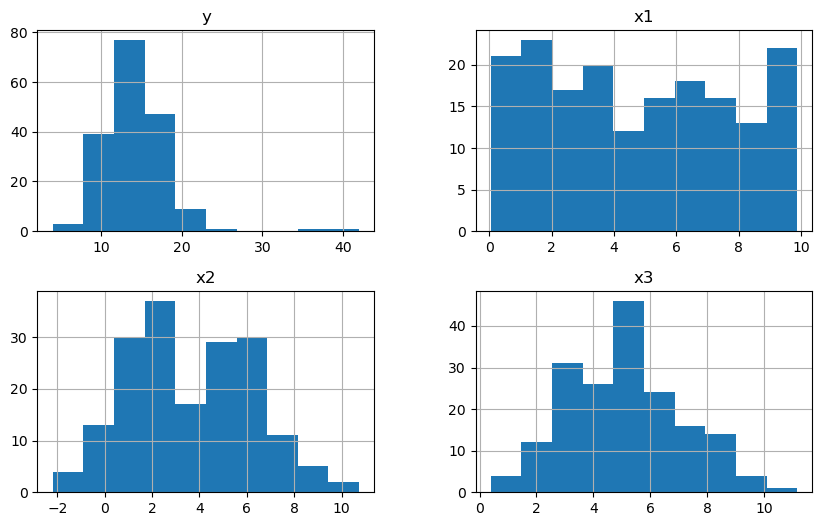

In [10]:
data.hist(figsize=(10, 6))
plt.show()

y tiene casi todo entre 8 y 23 y unos pocos valores sueltos cerca de 40, que son los raros. x1 está repartida parejo de 0 a 10, y x2 y x3 tienen forma más de campana. Fuera de y, ningún rango se ve imposible.

In [11]:
data.tail()

,y,x1,x2,x3,grupo
178,16.106776,9.367300,8.592049,8.046248,A
179,12.905459,1.375209,1.056612,6.077820,A
180,42.000000,9.800000,8.000000,5.000000,A
181,4.000000,0.400000,0.200000,5.000000,C
182,38.000000,9.500000,9.200000,8.000000,B


Las últimas 3 filas (180, 181 y 182) tienen números redondos (42.0, 9.8, 8.0...), cuando todas las demás tienen muchos decimales, y ahí están los valores más extremos de y (42, 4 y 38). Parece que se agregaron a mano; lo reviso con los residuos.

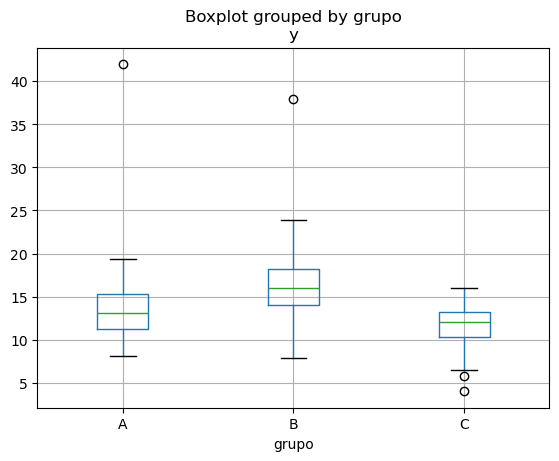

In [12]:
data.boxplot(column="y", by="grupo")
plt.show()

B tiene la mediana más alta (16), luego A (13) y al final C (12). El 42 de A y el 38 de B se salen de todo. El grupo sí cambia la y, así que tiene que entrar al modelo.

In [13]:
data[["y", "x1", "x2", "x3"]].corr()

,y,x1,x2,x3
y,1.000000,0.540937,0.527634,0.291556
x1,0.540937,1.000000,0.881887,-0.024775
x2,0.527634,0.881887,1.000000,-0.025579
x3,0.291556,-0.024775,-0.025579,1.000000


y se relaciona con x1 y x2 (0.54 y 0.53) y menos con x3 (0.29). x1 y x2 tienen 0.88 entre ellas: casi dan la misma información, así que puede haber colinealidad.

## 2. Modelo lineal múltiple

In [14]:
data["grupo_B"] = (data["grupo"] == "B").astype(int)
data["grupo_C"] = (data["grupo"] == "C").astype(int)  # A queda como grupo de referencia
data[["grupo", "grupo_B", "grupo_C"]].head()

,grupo,grupo_B,grupo_C
0,B,1,0
1,A,0,0
2,A,0,0
3,A,0,0
4,B,1,0


Convertí grupo en dos columnas de 0 y 1, como hombre = 1 y mujer = 0 en el lab 3. No hace falta una columna para A: si B y C valen 0, es A. Así A queda como referencia.

In [15]:
x = data[["x1", "x2", "x3", "grupo_B", "grupo_C"]]
y = data["y"]

lr = LinearRegression()
lr.fit(x, y)
y_pred = lr.predict(x)

print("b0 =", lr.intercept_)
print("Coeficientes:", lr.coef_)
print("R2 =", lr.score(x, y))
print("MSE train =", np.mean((y - y_pred) ** 2))

b0 = 6.456902214627421
Coeficientes: [ 0.63754897  0.2333242   0.6652717   2.69734601 -2.25772832]
R2 = 0.5935012316808936
MSE train = 7.242848886840939


Manteniendo lo demás constante, por cada unidad más de x1 la y aumenta en promedio 0.64, con x2 0.23 y con x3 0.67. El grupo B tiene la y 2.70 más alta que A y el C 2.26 más baja. El modelo explica el 59% de la variación de y (R2 de 0.59), con datos que todavía tienen errores.

¿Cuál fue el error? Hice `lr.fit(x, y)` con una sola columna (`x_1`) que además seguía siendo texto. Así sería regresión simple, sklearn pide una tabla y no una columna, y grupo nunca entró al modelo.

¿Cuál es la corrección? Usar x1, x2, x3 y grupo convertido a columnas de 0 y 1, con doble corchete para que x sea tabla.

¿Por qué se cometió el error? No me acordaba de cómo meter una variable categórica al modelo.

¿Cómo evitarlo en el futuro? Separar desde el inicio las variables numéricas y las categóricas, y convertir las categóricas a números antes del modelo.

In [16]:
n = len(data)
p = 6  # 5 coeficientes mas el intercepto
residuo = y - y_pred
rss = np.sum(residuo ** 2)
sigma2 = rss / (n - p)

x_unos = x.copy()
x_unos["unos"] = np.ones(n)  # Columna de unos para el intercepto, como en el lab 2
X = x_unos.values
var_beta = np.linalg.inv(X.T @ X) * sigma2  # Formula del addendum del lab 2
error_b = np.sqrt(np.diag(var_beta))

coef = np.append(lr.coef_, lr.intercept_)
t = coef / error_b
for i in range(len(coef)):
    print(x_unos.columns[i], " coef:", coef[i], " t:", t[i])

x1  coef: 0.6375489718482522  t: 4.284005516783277
x2  coef: 0.2333241952650918  t: 1.3739590947087565
x3  coef: 0.66527170260364  t: 6.459414696166848
grupo_B  coef: 2.69734601386319  t: 5.668192250376056
grupo_C  coef: -2.257728322087943  t: -4.228360269959321
unos  coef: 6.456902214627421  t: 9.342495499448747


Con la regla del lab 2 (|t| mayor a 2), todas las variables son significativas menos x2 (t de 1.37). Tiene sentido: x2 casi repite lo que ya dice x1.

## 3. Los 6 errores comunes

### 1) No linealidad y 6) heterocedasticidad

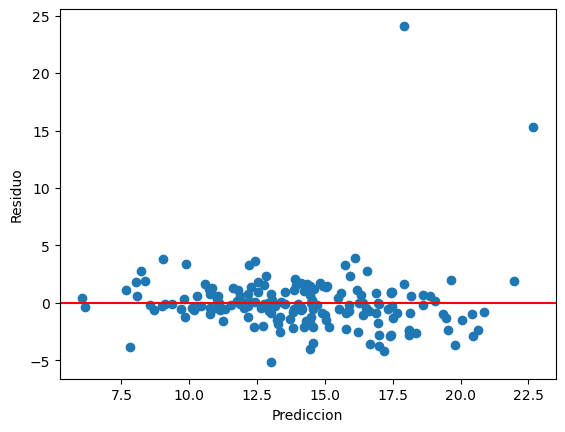

In [17]:
plt.scatter(y_pred, residuo)
plt.axhline(0, color="red")
plt.xlabel("Prediccion")
plt.ylabel("Residuo")
plt.show()

Los residuos están alrededor de 0 sin formar curva, así que no hay no linealidad. Pero dos puntos se van muy arriba (residuos de 24 y 15) y el modelo no puede explicarlos.

In [18]:
mitad = np.median(y_pred)
print("Desviacion de residuos, predicciones bajas:", np.std(residuo[y_pred < mitad]))
print("Desviacion de residuos, predicciones altas:", np.std(residuo[y_pred >= mitad]))

Desviacion de residuos, predicciones bajas: 1.4493270028552836
Desviacion de residuos, predicciones altas: 3.5162470689428953


La dispersión de los residuos es 1.45 en las predicciones bajas y 3.52 en las altas. Parece heterocedasticidad, pero en la parte alta caen las filas 180 y 182; lo reviso otra vez sin ellas.

### 2) Correlación de los errores

In [19]:
r = residuo.values
dw = np.sum((r[1:] - r[:-1]) ** 2) / np.sum(r ** 2)  # Durbin-Watson: cerca de 2 es que no hay correlacion
dw

np.float64(2.052668246665003)

El Durbin-Watson es 2.05, prácticamente 2, así que un error no depende del anterior.

### 3) Colinealidad

In [20]:
for col in ["x1", "x2", "x3"]:
    otras = data[["x1", "x2", "x3"]].drop(columns=[col])
    lr_vif = LinearRegression()
    lr_vif.fit(otras, data[col])
    r2 = lr_vif.score(otras, data[col])
    print(col, "VIF =", 1 / (1 - r2))  # VIF = 1 / (1 - R2) de explicar esa variable con las demas

x1 VIF = 4.499028830438657
x2 VIF = 4.499211019262729
x3 VIF = 1.0006768726857485


x1 y x2 tienen VIF de 4.5. No pasa de 10, pero viene de su correlación de 0.88 y explica por qué x2 no sale significativa. En la sección 4 pruebo un modelo sin x2.

### 4) Outliers

In [21]:
residuo_est = residuo / np.sqrt(sigma2)
data["residuo_est"] = residuo_est
data[np.abs(residuo_est) > 3]

,y,x1,x2,x3,grupo,grupo_B,grupo_C,residuo_est
180,42.0,9.8,8.0,5.0,A,0,0,8.803504
182,38.0,9.5,9.2,8.0,B,1,0,5.595852


Las filas 180 y 182 tienen residuos de 8.8 y 5.6 desviaciones estándar, muy por encima de 3. Son dos de las filas con números redondos del final del archivo.

### 5) Puntos de alto leverage

In [22]:
H = X @ np.linalg.inv(X.T @ X) @ X.T
leverage = np.diag(H)
limite = 2 * p / n
print("Limite 2p/n:", limite)
data[leverage > limite]

Limite 2p/n: 0.06741573033707865


,y,x1,x2,x3,grupo,grupo_B,grupo_C,residuo_est
12,16.398547,4.271000,6.869650,6.248240,A,0,0,0.532926
66,5.796780,1.409242,2.356593,0.752209,C,0,1,-0.128252
73,12.789632,8.154614,10.739239,3.846193,C,0,1,-0.611075
126,15.926778,8.180148,2.245590,0.865116,B,1,0,0.167214
162,23.856925,6.335297,5.726907,11.157762,B,1,0,0.695613


5 filas pasan el límite de 0.067, pero todas tienen residuos chicos (menos de 1 desviación), o sea que el modelo las predice bien. Un punto con leverage alto solo es problema si además está mal predicho, así que no las elimino.

### Error del archivo 5: filas agregadas a mano

In [23]:
data.loc[[180, 181, 182]]

,y,x1,x2,x3,grupo,grupo_B,grupo_C,residuo_est
180,42.0,9.8,8.0,5.0,A,0,0,8.803504
181,4.0,0.4,0.2,5.0,C,0,1,-1.397921
182,38.0,9.5,9.2,8.0,B,1,0,5.595852


Elimino las filas 180, 181 y 182. Son las últimas del archivo, tienen números redondos cuando las demás tienen muchos decimales, y tienen los valores más extremos de y. La 180 y la 182 son outliers enormes. La 181 no pasa de 3, pero es del mismo bloque agregado a mano, así que también es un error del archivo y no una observación real.

In [24]:
data = data.drop(index=[180, 181, 182])
x = data[["x1", "x2", "x3", "grupo_B", "grupo_C"]]
y = data["y"]

lr = LinearRegression()
lr.fit(x, y)
y_pred = lr.predict(x)
residuo = y - y_pred

n = len(data)
sigma2 = np.sum(residuo ** 2) / (n - p)
residuo_est = residuo / np.sqrt(sigma2)

print("Filas:", n)
print("Coeficientes:", lr.coef_)
print("R2 =", lr.score(x, y))
print("MSE train =", np.mean(residuo ** 2))
data["residuo_est"] = residuo_est
data[np.abs(residuo_est) > 3]

Filas: 175
Coeficientes: [ 0.6143525   0.0689763   0.58486167  2.80994609 -1.72075882]
R2 = 0.7642429306134942
MSE train = 2.3071588029098082


,y,x1,x2,x3,grupo,grupo_B,grupo_C,residuo_est
145,7.87235,0.368869,1.071209,5.070527,B,1,0,-3.500231


Sin esas filas el R2 sube de 0.59 a 0.76 y el MSE baja de 7.24 a 2.31. Ahora la fila 145 queda en -3.5. No la elimino: sus valores son normales y no hay nada que la haga ver como error de captura. Con 175 datos es esperable que alguno pase de 3, y quitarla solo serviría para que el modelo se vea mejor.

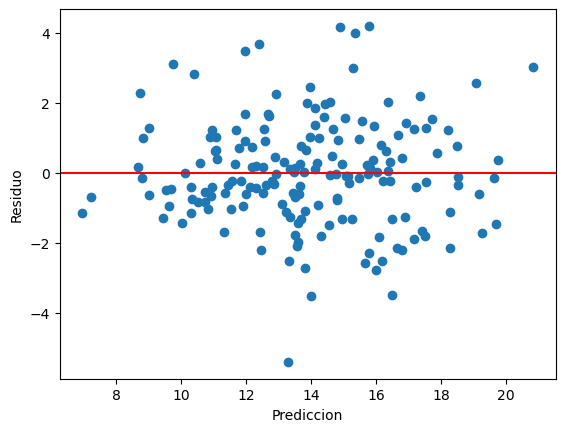

Desviacion de residuos, predicciones bajas: 1.3495929481094189
Desviacion de residuos, predicciones altas: 1.663135167716058


In [25]:
plt.scatter(y_pred, residuo)
plt.axhline(0, color="red")
plt.xlabel("Prediccion")
plt.ylabel("Residuo")
plt.show()

mitad = np.median(y_pred)
print("Desviacion de residuos, predicciones bajas:", np.std(residuo[y_pred < mitad]))
print("Desviacion de residuos, predicciones altas:", np.std(residuo[y_pred >= mitad]))

Sin las filas agregadas, los residuos quedan repartidos parejo alrededor de 0, sin curva ni forma de embudo. La dispersión es 1.35 abajo y 1.66 arriba, ya parecida, así que la heterocedasticidad de antes era por los outliers.

Resumen de los 6 errores:
- No linealidad: no hay, los residuos no forman curva.
- Correlación de errores: no hay, Durbin-Watson de 2.05.
- Colinealidad: moderada entre x1 y x2 (VIF de 4.5); pruebo quitar x2.
- Outliers: 180 y 182, eliminadas junto con la 181 por ser filas agregadas a mano.
- Alto leverage: 5 filas, pero bien predichas; se quedan.
- Heterocedasticidad: era por los outliers; sin ellos la dispersión es pareja.

## 4. Mejora y comparación de modelos

Comparo modelos con validación cruzada de 10 folds, como en el lab 5, para medir el error con datos que el modelo no vio.

In [26]:
kf = KFold(n_splits=10, shuffle=True, random_state=0)
mse_prom = np.mean((y - np.mean(y)) ** 2)  # Error si siempre predecimos el promedio, como el TSS del lab 1

x_1 = data[["x1", "x2", "x3"]]
x_2 = data[["x1", "x2", "x3", "grupo_B", "grupo_C"]]
x_3 = data[["x1", "x3", "grupo_B", "grupo_C"]]

mse_1 = -cross_val_score(LinearRegression(), x_1, y, cv=kf, scoring="neg_mean_squared_error")  # sklearn da el MSE negativo
mse_2 = -cross_val_score(LinearRegression(), x_2, y, cv=kf, scoring="neg_mean_squared_error")
mse_3 = -cross_val_score(LinearRegression(), x_3, y, cv=kf, scoring="neg_mean_squared_error")

print("Promedio, sin modelo:  MSE", mse_prom)
print("M1 sin grupo:          MSE", mse_1.mean(), " desv", mse_1.std())
print("M2 todas:              MSE", mse_2.mean(), " desv", mse_2.std())
print("M3 sin x2:             MSE", mse_3.mean(), " desv", mse_3.std())

Promedio, sin modelo:  MSE 9.786170183204124
M1 sin grupo:          MSE 5.554317149777781  desv 1.5139700526993147
M2 todas:              MSE 2.4535028216008063  desv 0.8274080827957022
M3 sin x2:             MSE 2.4312772435994066  desv 0.84012832580467


Sin grupo (M1) el error es más del doble (5.55), así que grupo es la variable más importante. Con todas (M2) el MSE es 2.45 y sin x2 (M3) baja un poco a 2.43: quitar x2 no hace perder nada y deja un modelo más simple.

In [27]:
# Pipeline para que el escalador solo aprenda del train de cada fold
for i in [0.1, 1, 10, 100]:
    ridge = make_pipeline(StandardScaler(), Ridge(alpha=i))
    mse_ridge = -cross_val_score(ridge, x_2, y, cv=kf, scoring="neg_mean_squared_error")
    print("Ridge alpha =", i, " MSE", mse_ridge.mean())

for i in [0.01, 0.1, 0.5, 1]:
    lasso = make_pipeline(StandardScaler(), Lasso(alpha=i))
    mse_lasso = -cross_val_score(lasso, x_2, y, cv=kf, scoring="neg_mean_squared_error")
    print("Lasso alpha =", i, " MSE", mse_lasso.mean())

Ridge alpha = 0.1  MSE 2.4533513916099396
Ridge alpha = 1  MSE 2.4526097042948867
Ridge alpha = 10  MSE 2.4791678856470556
Ridge alpha = 100  MSE 3.3035267396925163
Lasso alpha = 0.01  MSE 2.4524295583094435
Lasso alpha = 0.1  MSE 2.4861376100652413
Lasso alpha = 0.5  MSE 3.4342871825810497
Lasso alpha = 1  MSE 6.1704265202943045


Penalizar no mejora: el mejor Ridge (alpha 1) y el mejor Lasso (alpha 0.01) dan 2.45, igual que M2, y con alpha grande el error sube. Igual que en el lab 4 y en California del lab 5, el modelo no está sobreajustado, así que no hay nada que penalizar.

In [28]:
lr_3 = LinearRegression()
lr_3.fit(x_3, y)
print("M3 MSE train:", np.mean((y - lr_3.predict(x_3)) ** 2))
print("M3 MSE validacion:", mse_3.mean())

M3 MSE train: 2.314138827315692
M3 MSE validacion: 2.4312772435994066


El MSE de entrenamiento (2.31) y el de validación (2.43) son casi iguales, así que no hay sobreajuste. Por eso Ridge y Lasso no ayudaron.

## 5. Validación cruzada y conclusión

In [29]:
loo = LeaveOneOut()
mse_loo_2 = -cross_val_score(LinearRegression(), x_2, y, cv=loo, scoring="neg_mean_squared_error")
mse_loo_3 = -cross_val_score(LinearRegression(), x_3, y, cv=loo, scoring="neg_mean_squared_error")

print("M2 LOOCV MSE:", mse_loo_2.mean())
print("M3 LOOCV MSE:", mse_loo_3.mean())
print("R2 de validacion M3:", 1 - mse_3.mean() / mse_prom)  # Misma idea que 1 - RSS/TSS del lab 1

M2 LOOCV MSE: 2.484053553667416
M3 LOOCV MSE: 2.45913903703267
R2 de validacion M3: 0.7515598852171838


Con LOOCV también gana M3 (2.46 contra 2.48), así que el resultado no depende de cómo se armaron los folds. M3 explica el 75% de la variación de y en datos que no vio.

In [30]:
print("b0 =", lr_3.intercept_)
for i in range(len(x_3.columns)):
    print(x_3.columns[i], lr_3.coef_[i])

b0 = 7.201417848956482
x1 0.6672433881778103
x3 0.5837941131535945
grupo_B 2.8375571574726073
grupo_C -1.7067223115133665


Modelo final (M3): y = 7.20 + 0.67 x1 + 0.58 x3 + 2.84 B - 1.71 C

Manteniendo lo demás constante, por cada unidad más de x1 la y aumenta en promedio 0.67, y por cada unidad de x3, 0.58. El grupo B tiene la y 2.84 más alta que A y el C 1.71 más baja. El 7.20 es la y esperada en el grupo A con x1 y x3 en 0. Es asociación: no quiere decir que x1 o x3 causen el cambio en y.

### ¿Por qué cometí los errores del examen?

En general no supe hacer nada del notebook, desde las librerías que tenía que usar hasta cómo iniciar el Python. Como no tenía nada en mi .ipynb, no pude corregir más que empezar todo de 0.

Fue exceso de confianza: estudié poco para el examen y me bloqueé al momento. No sabía qué librerías usar por no tener los apuntes que debía haber hecho durante el primer módulo, no le di la práctica suficiente a la materia y me atrasé por no ponerme al corriente con algunos códigos de clase.

Para evitarlo ya tengo un cuaderno con mis apuntes nuevos y los de las clases pasadas. En clase voy a preguntar mis dudas y asistir a las asesorías necesarias, y en general practicar más lo que aprenda y darle más dedicación a cada clase y tarea.

### Conclusión

El archivo tenía 5 errores deliberados: x1 con coma decimal, etiquetas de grupo mal escritas, grupo vacío o con D, datos faltantes en x2 y x3, y 3 filas agregadas a mano al final. Eliminé 8 de 183 filas y justifiqué cada una; quedan 175.

De los 6 errores comunes, los problemas reales eran los outliers (que también causaban la aparente heterocedasticidad) y la colinealidad entre x1 y x2.

El mejor modelo usa x1, x3 y grupo. En validación cruzada tiene MSE de 2.43 con 10 folds y 2.46 con LOOCV, y explica el 75% de la variación de y en datos que no vio. Lo que más explica a y es el grupo; x2 sobra porque repite lo de x1, y penalizar no mejora porque el modelo no está sobreajustado.